# 🚦 YOLOv8 Traffic Sign Detection - Training Notebook

## 📁 Cấu trúc thư mục dự án
```
Traffic_Sign_Project/
├── Data_Pipeline/          # Xử lý dữ liệu
├── Training/               # (Notebook này)
│   ├── yolov8-detectsign.ipynb
│   └── cnn-detectsign.ipynb
├── Inference/              # Chạy inference
│   ├── Model_hybrid.py
│   ├── best.pt             # ← Model YOLO sau khi train
│   └── traffic_sign_cnn.keras
└── Utils/
    └── helper_functions.py
```

## 🎯 Hướng dẫn sử dụng
1. **Upload notebook này lên Kaggle/Colab** (cần GPU)
2. **Upload dataset** đã xử lý từ `output_Yolodataset/` lên Kaggle
3. **Chạy các cells** theo thứ tự
4. **Download model** `best.pt` và copy vào `Inference/`

## ⚙️ Lưu ý về đường dẫn
- Các đường dẫn trong notebook được cấu hình cho **Kaggle environment**
- Nếu chạy local, cần sửa `INPUT_DATASET_DIR` và các paths khác

In [1]:
!pip install ultralytics -q
!pip install wandb -q

import os
import torch
from ultralytics import YOLO

# Kiểm tra GPU & PyTorch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
!nvidia-smi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch version: 2.8.0+cu126
CUDA available: True
Sun Jan  4 16:13:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 570.172.08             Driver Version: 570.172.08     CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |  

In [2]:
# [CELL 2] FIX DATA PATHS & CONFIG
import yaml
import os

# 1. Đường dẫn gốc tới dataset trên Kaggle
# Lưu ý: Đây là đường dẫn folder chứa file data.yaml
INPUT_DATASET_DIR = '/kaggle/input/vietnam-traffic-sign-yolov8-sota-v2'

# 2. Đọc file data.yaml gốc (đang bị lỗi path Windows)
original_yaml_path = os.path.join(INPUT_DATASET_DIR, 'data.yaml')

with open(original_yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)

# 3. Sửa lại đường dẫn thành đường dẫn tuyệt đối trên Kaggle
# Xóa key 'path' nếu có để tránh gây nhiễu, chỉ dùng train/val/test tuyệt đối
if 'path' in data_config:
    del data_config['path']

# Trỏ thẳng vào vị trí ảnh trên Kaggle
data_config['train'] = os.path.join(INPUT_DATASET_DIR, 'train', 'images')
data_config['val']   = os.path.join(INPUT_DATASET_DIR, 'val', 'images')
data_config['test']  = os.path.join(INPUT_DATASET_DIR, 'test', 'images')

# In ra để kiểm tra
print("Cấu hình data mới (đã sửa path):")
print(data_config)

# 4. Lưu file yaml đã sửa vào thư mục làm việc (/kaggle/working)
FIXED_YAML_PATH = '/kaggle/working/data_fixed.yaml'
with open(FIXED_YAML_PATH, 'w') as f:
    yaml.dump(data_config, f)

print(f"\n✅ Đã tạo file config mới tại: {FIXED_YAML_PATH}")

# 5. Đường dẫn tới file hyperparameters (giữ nguyên)
HYPER_YAML_PATH = os.path.join(INPUT_DATASET_DIR, 'training_config.yaml')

Cấu hình data mới (đã sửa path):
{'names': ['Prohibitory', 'Danger', 'Mandatory'], 'nc': 3, 'test': '/kaggle/input/vietnam-traffic-sign-yolov8-sota-v2/test/images', 'train': '/kaggle/input/vietnam-traffic-sign-yolov8-sota-v2/train/images', 'val': '/kaggle/input/vietnam-traffic-sign-yolov8-sota-v2/val/images'}

✅ Đã tạo file config mới tại: /kaggle/working/data_fixed.yaml


In [3]:
# [CELL 3] START TRAINING
from ultralytics import YOLO

# Load model
model = YOLO('yolov8s.pt') 

# Bắt đầu huấn luyện
# LƯU Ý: Tham số data bây giờ trỏ vào FIXED_YAML_PATH vừa tạo ở trên
results = model.train(
    data=FIXED_YAML_PATH,   # <--- Dùng file đã sửa path
    cfg=HYPER_YAML_PATH,    # File hyperparams (Mosaic, Augment...)
    epochs=50,
    imgsz=1280,
    device=[0, 1],  
    batch=32,
    project='Traffic_Sign_Project',
    name='train_fixed_path',
    exist_ok=True,
    verbose=True
)

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.3.247 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
                                                       CUDA:1 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=/kaggle/input/vietnam-traffic-sign-yolov8-sota-v2/training_config.yaml, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_fixed.yaml, degrees=8.0, deterministic=True, device=0,1, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=1280, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, m

1. Confusion Matrix (Ma trận nhầm lẫn):


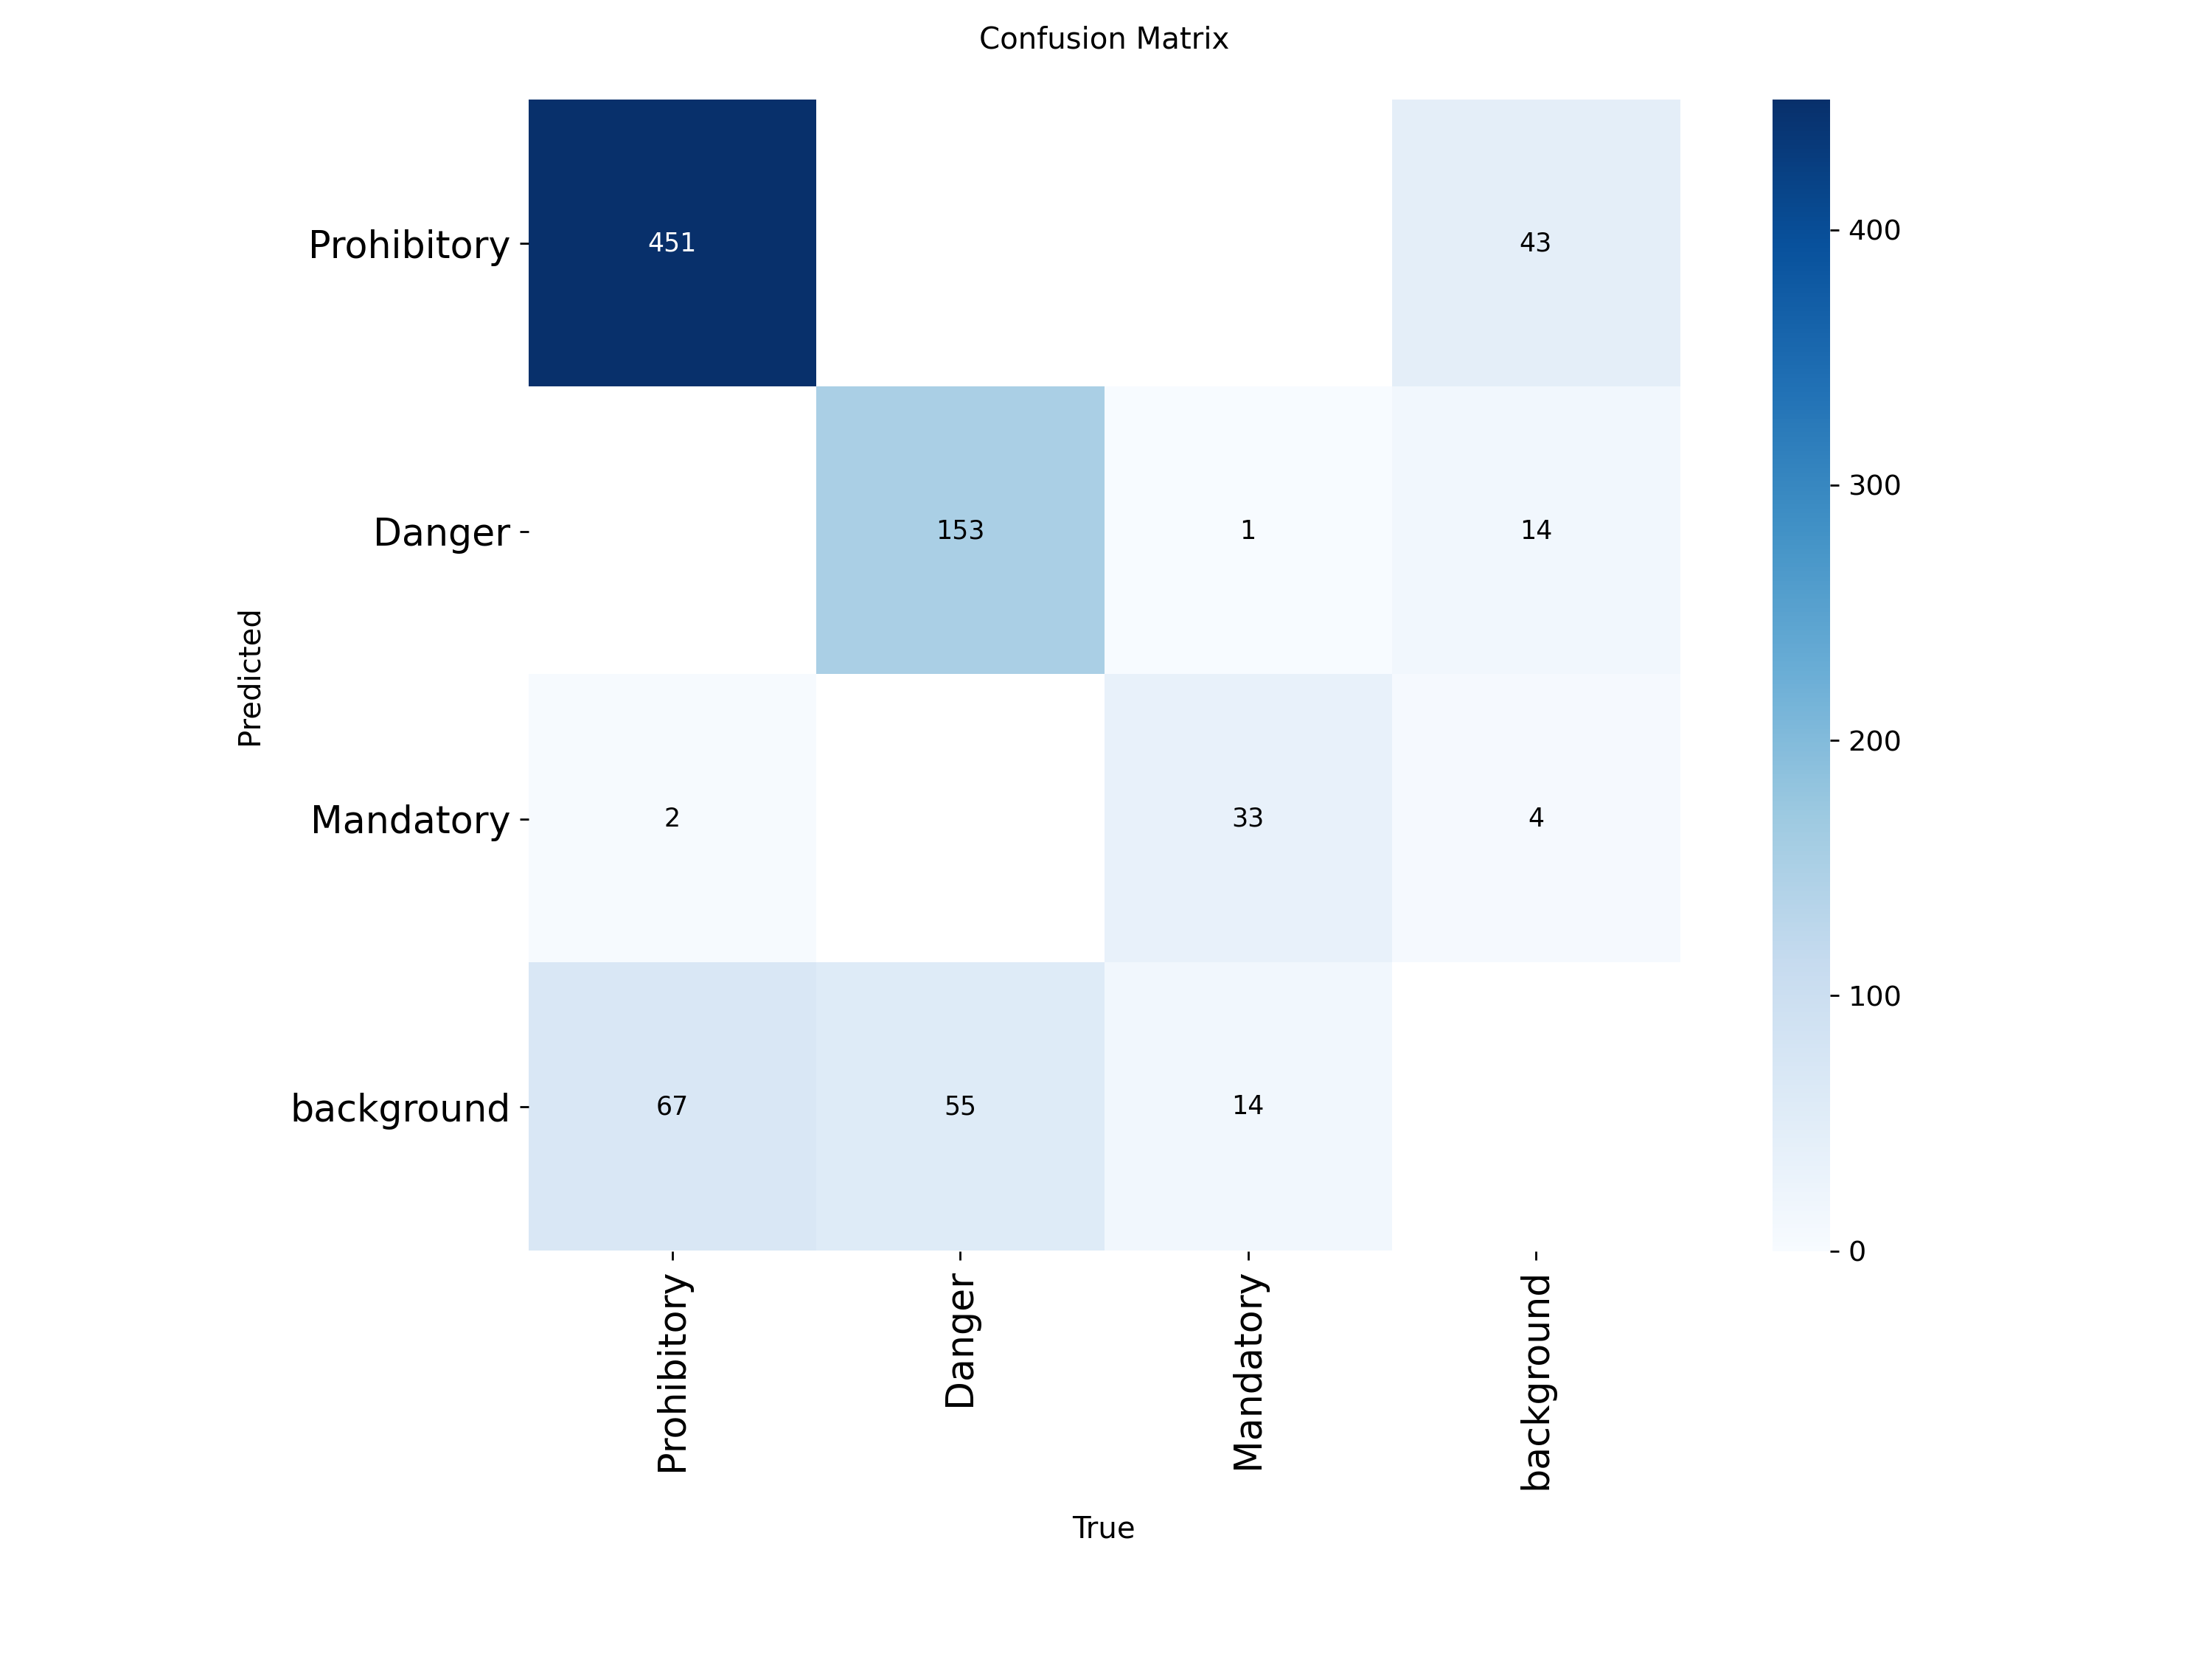


2. Kết quả Training (Loss, mAP):


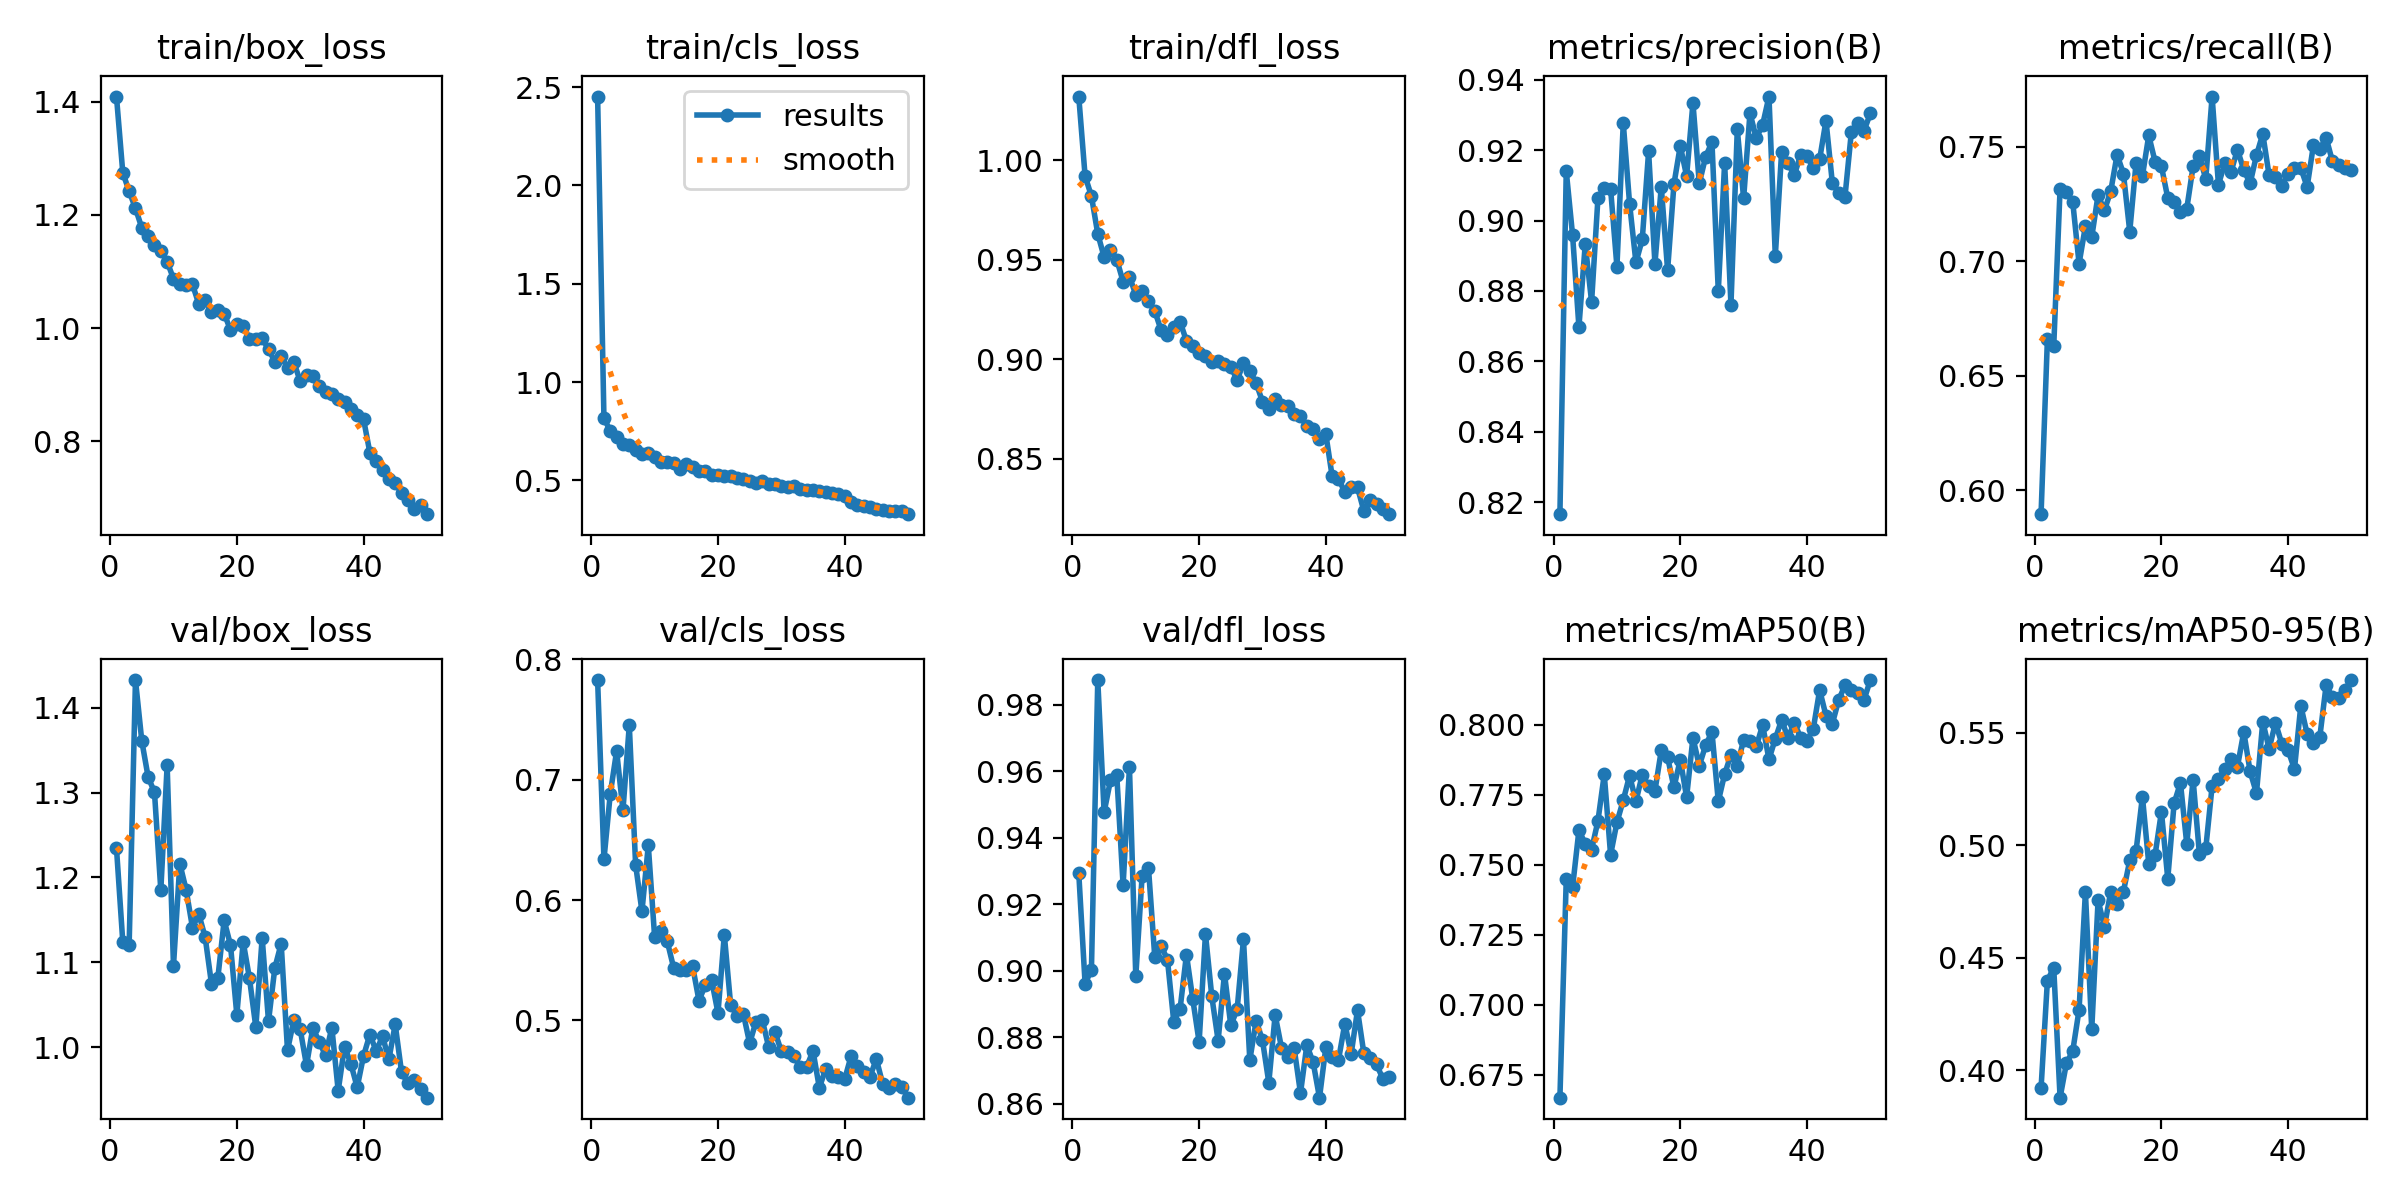


3. Một số mẫu dự đoán trên tập Val:


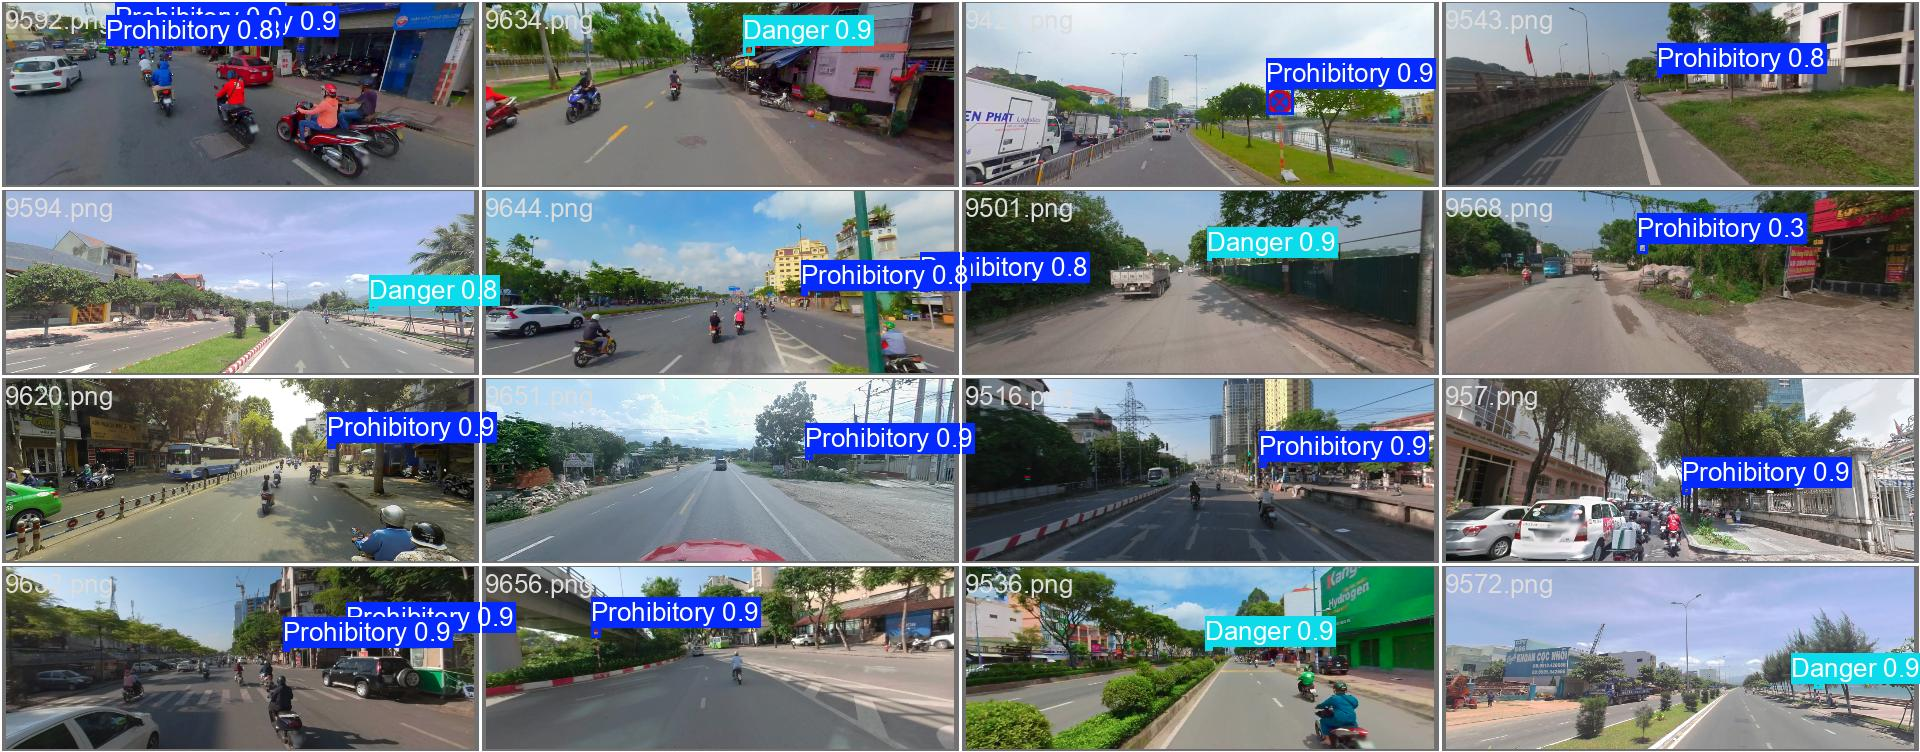

In [4]:
# [CELL 4] EVALUATION & SHOW RESULTS
from IPython.display import Image, display

# Đường dẫn tới thư mục kết quả vừa train
result_dir = '/kaggle/working/Traffic_Sign_Project/train_fixed_path'

print("1. Confusion Matrix (Ma trận nhầm lẫn):")
display(Image(filename=f'{result_dir}/confusion_matrix.png'))

print("\n2. Kết quả Training (Loss, mAP):")
display(Image(filename=f'{result_dir}/results.png'))

print("\n3. Một số mẫu dự đoán trên tập Val:")
display(Image(filename=f'{result_dir}/val_batch0_pred.jpg'))

In [5]:
# [CELL 5] ZIP & DOWNLOAD
import shutil

# Nén thư mục kết quả
shutil.make_archive('My_Traffic_Model', 'zip', '/kaggle/working/Traffic_Sign_Project')

print("✅ Đã nén xong! Hãy vào tab 'Output' bên phải để tải file 'My_Traffic_Model.zip' về.")

✅ Đã nén xong! Hãy vào tab 'Output' bên phải để tải file 'My_Traffic_Model.zip' về.
